# Airline Passenger Satisfaction — Exploratory analysis and feature engineering

**Goal of the project:** predict whether a passenger is *satisfied* or *neutral or dissatisfied*
from their profile, their trip and their ratings of 14 services, and explain which factors drive satisfaction.

This notebook covers the first stage asked by our supervisor: **understand the data, visualise it,
interpret what we see, and derive the feature-engineering choices** that the models will use.
Every choice below is backed by a number or a figure. Figures are also saved in `reports/figures/`.

| Section | Content |
|---|---|
| 1 | Dataset overview and target balance |
| 2 | Passenger and trip characteristics |
| 3 | Service ratings, including the meaning of a 0 rating |
| 4 | Delays |
| 5 | Redundancy between ratings |
| 6 | Interactions between categories |
| 7 | Feature engineering |
| 8 | Preliminary check: does the feature engineering help? |
| 9 | Summary and next steps |

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # make the src package importable from notebooks/

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.feature_selection import mutual_info_classif

from src import visualization as viz
from src.data import load_split, split_features_target
from src.preprocessing import build_baseline_preprocessor, build_feature_engineer, build_preprocessor
from src.utils import load_config, project_path

pd.set_option("display.max_columns", 50)
config = load_config()
FIGURES = project_path(config["paths"]["figures_dir"])
RATINGS = config["features"]["ratings"]
CATEGORICAL = config["features"]["categorical"]
NUMERIC = config["features"]["numeric"]

train = load_split(config, "train")
test = load_split(config, "test")
X_train, y_train = split_features_target(train, config)
X_test, y_test = split_features_target(test, config)

## 1. Dataset overview

In [2]:
print(f"train: {train.shape[0]:,} rows, test: {test.shape[0]:,} rows, {X_train.shape[1]} features")
overview = pd.DataFrame({
    "dtype": X_train.dtypes.astype(str),
    "unique values": X_train.nunique(),
    "missing (train)": X_train.isna().sum(),
    "missing (test)": X_test.isna().sum(),
})
display(overview)
print("duplicated rows in train:", train.duplicated().sum())

train: 103,904 rows, test: 25,976 rows, 22 features


,dtype,unique values,missing (train),missing (test)
gender,str,2,0,0
customer_type,str,2,0,0
age,int64,75,0,0
type_of_travel,str,2,0,0
class,str,3,0,0
flight_distance,int64,3802,0,0
inflight_wifi_service,int64,6,0,0
departure_arrival_time_convenient,int64,6,0,0
ease_of_online_booking,int64,6,0,0
gate_location,int64,6,0,0


duplicated rows in train: 0


satisfied: train 43.3%, test 43.9%


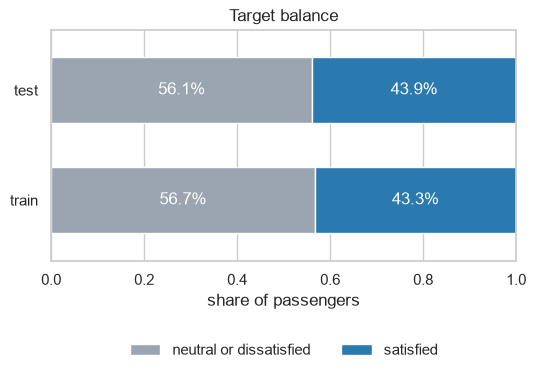

In [3]:
viz.plot_target_balance(y_train, y_test, FIGURES);
print(f"satisfied: train {y_train.mean():.1%}, test {y_test.mean():.1%}")

**Interpretation**

- The data is already split into **103,904 training** and **25,976 test** passengers (80 / 20).
  The test file stays untouched until the final evaluation; all exploration below uses the training set only.
- There are **22 features**: 4 categorical (gender, customer type, type of travel, class), 4 numeric
  (age, flight distance, departure and arrival delays) and **14 service ratings** on a 0–5 scale.
- Data quality is good: **no duplicated rows**, and the only missing values are in
  `arrival_delay_in_minutes` (310 rows, 0.3 % of train). Section 4 shows how to fill them.
- The target is **moderately imbalanced: 43.3 % satisfied** vs 56.7 % neutral or dissatisfied, with the same
  proportion in the test file (43.9 %). A model that always answers "dissatisfied" would already reach 56.7 %
  accuracy, so we will also report F1-score and ROC-AUC, not only accuracy.

## 2. Passenger and trip characteristics

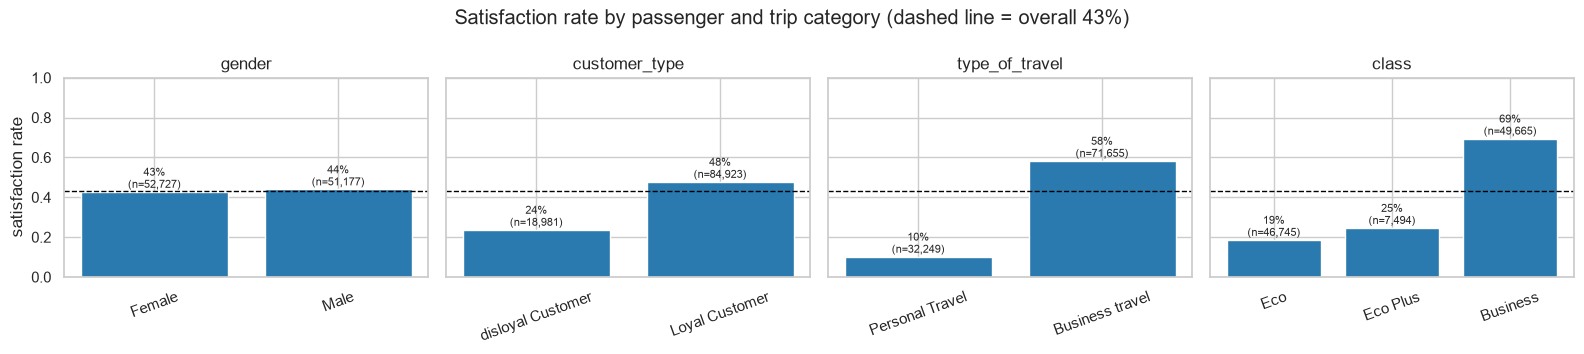

In [4]:
viz.plot_rate_by_category(X_train, y_train, CATEGORICAL, FIGURES);

**Interpretation**

- **Type of travel is the strongest categorical factor:** 58 % of business travellers are satisfied,
  against only **10 %** of personal travellers.
- **Class** follows: 69 % satisfied in Business, 25 % in Eco Plus, 19 % in Eco.
- **Loyal customers** are twice as often satisfied as disloyal ones (48 % vs 24 %).
- **Gender has no effect** (43 % vs 44 %): it is a candidate for removal, which also avoids using a sensitive
  attribute without reason.

skewness: {'age': -0.0, 'flight_distance': 1.11, 'departure_delay_in_minutes': 6.73, 'arrival_delay_in_minutes': 6.6}


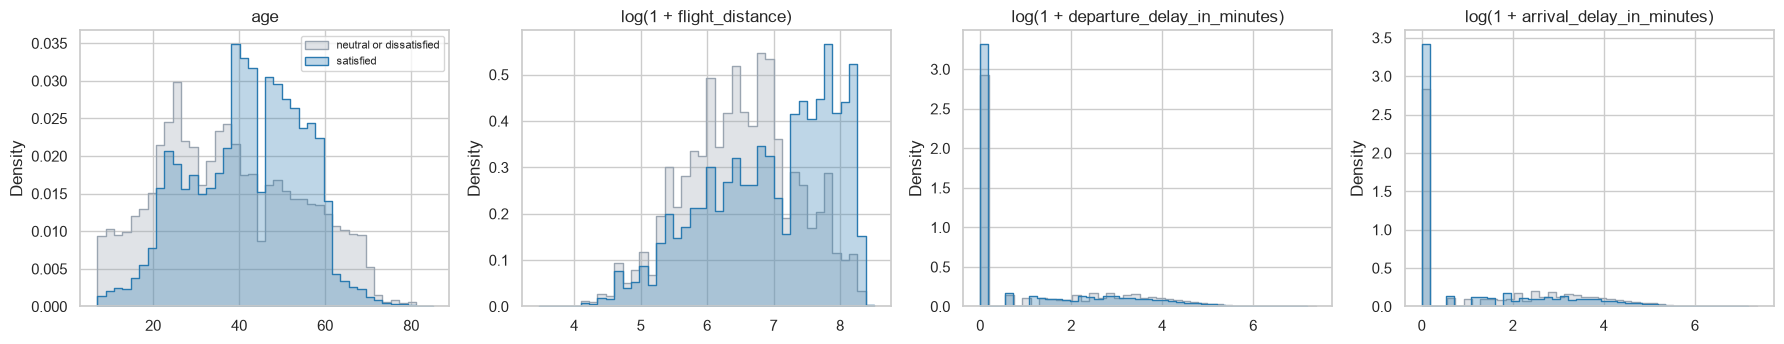

In [5]:
viz.plot_numeric_by_target(X_train, y_train, NUMERIC,
                           log_columns=["flight_distance", "departure_delay_in_minutes", "arrival_delay_in_minutes"],
                           figures_dir=FIGURES);
print("skewness:", X_train[NUMERIC].skew().round(2).to_dict())

median flight distance by class: {'Business': 1589.0, 'Eco': 599.0, 'Eco Plus': 589.0}


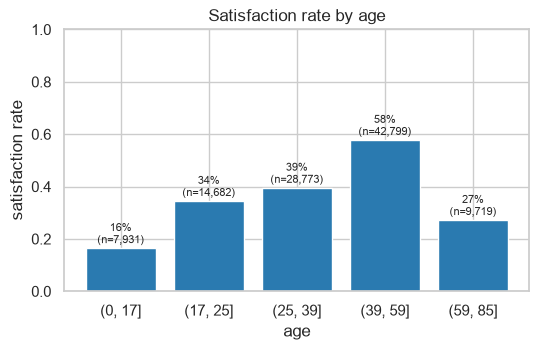

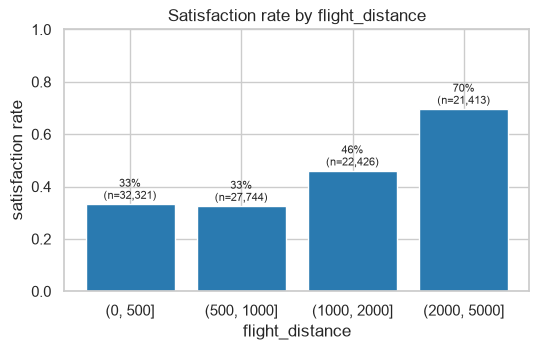

In [6]:
viz.plot_rate_by_bins(X_train, y_train, "age", [0, 17, 25, 39, 59, 85], FIGURES, "04a_rate_by_age");
viz.plot_rate_by_bins(X_train, y_train, "flight_distance", [0, 500, 1000, 2000, 5000], FIGURES, "04b_rate_by_distance");
print("median flight distance by class:", X_train.groupby("class")["flight_distance"].median().to_dict())

**Interpretation**

- **Age has a non-linear effect** (inverted U): 16 % of passengers under 18 are satisfied, 34 % at 18–25,
  39 % at 26–39, a peak of **58 % at 40–59**, then a drop to 27 % after 60. A linear model on raw age cannot
  represent a rise followed by a fall, so we add **age groups** as a categorical feature.
- **Longer flights have more satisfied passengers** (about 33 % under 1,000 miles, 46 % between 1,000 and 2,000,
  70 % beyond 2,000). Part of this is a **class effect**: Business-class flights are much longer
  (median 1,589 miles vs about 595 for Eco and Eco Plus). Distance alone must not be read as a cause.
- Flight distance (skewness 1.1) and both delays (skewness 6.6–6.7) are **strongly right-skewed**: most flights
  have no delay but a few have delays of several hours. We use **log(1 + x)** so that these extreme values do not
  dominate distance-based models (KNN) or the logistic-regression gradient.

## 3. Service ratings

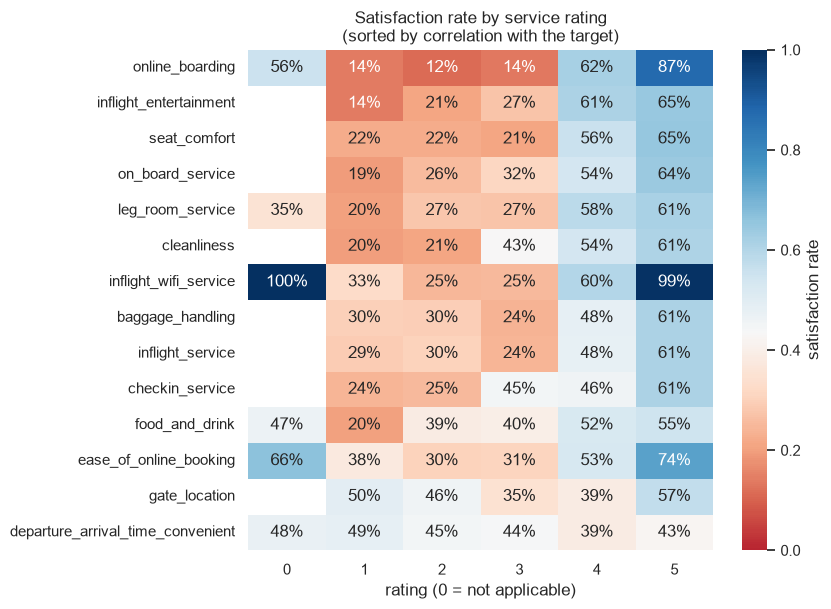

In [7]:
viz.plot_rating_heatmap(X_train, y_train, RATINGS, FIGURES);

,correlation with target,mutual information
online_boarding,0.504,0.211
inflight_wifi_service,0.284,0.162
inflight_entertainment,0.398,0.094
seat_comfort,0.349,0.079
leg_room_service,0.313,0.061
flight_distance,0.299,0.060
on_board_service,0.322,0.057
cleanliness,0.305,0.052
ease_of_online_booking,0.172,0.051
age,0.137,0.047


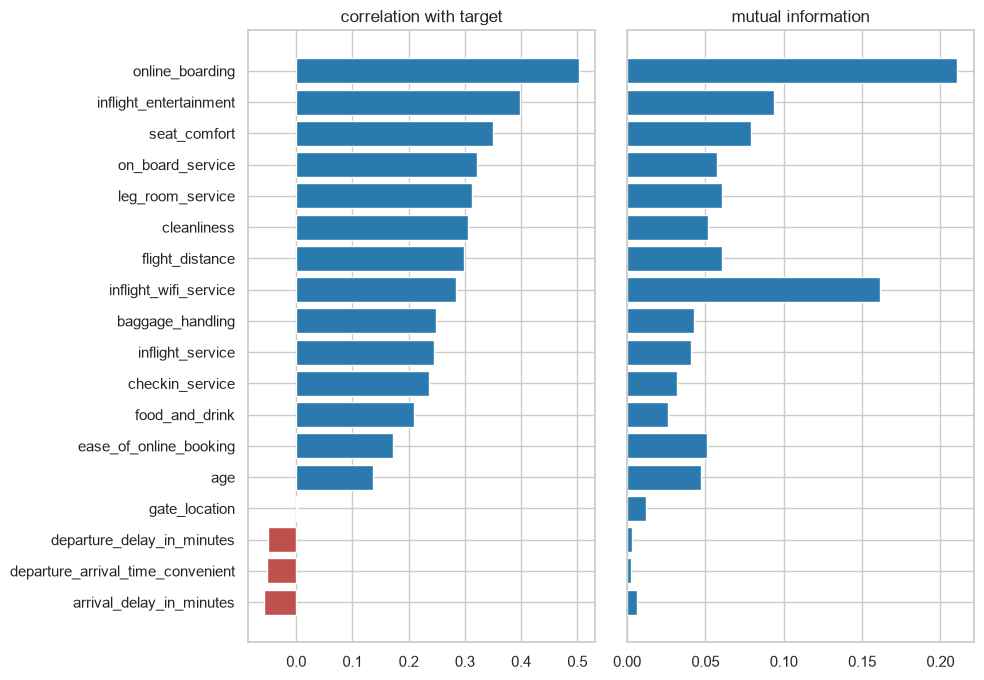

In [8]:
discrete = [True] * len(RATINGS) + [False] * len(NUMERIC)
relevance_inputs = X_train[RATINGS + NUMERIC].fillna(X_train[NUMERIC].median())
relevance = pd.DataFrame({
    "correlation with target": relevance_inputs.corrwith(y_train),
    "mutual information": mutual_info_classif(relevance_inputs, y_train, discrete_features=discrete,
                                              random_state=config["seed"]),
}, index=RATINGS + NUMERIC)
display(relevance.sort_values("mutual information", ascending=False).round(3))
viz.plot_feature_relevance(relevance, FIGURES);

**Interpretation**

- **Online boarding is the most important service** (correlation 0.50, highest mutual information):
  passengers who rate it 4 or 5 are mostly satisfied, those who rate it 1–3 almost never are.
- Then come **inflight entertainment, seat comfort, on-board service, leg room and cleanliness**
  (correlations 0.30–0.40): the comfort on board matters more than the steps before the flight.
- **Inflight wifi** shows why correlation is not enough: its correlation is only 0.28, yet its mutual information is
  the second highest. The heatmap explains it: ratings 1 to 3 give about 25–33 % satisfaction, 4 gives 60 %,
  and **5 gives 99 %**. The effect is a threshold, not a straight line, which correlation underestimates.
- **Gate location** (correlation 0.00) and **departure/arrival time convenience** (−0.05) carry almost no
  information: they are candidates for removal, to be confirmed with the models.

### 3.1 What does a rating of 0 mean?

In [9]:
zeros = pd.DataFrame({
    "number of 0": (X_train[RATINGS] == 0).sum(),
    "satisfaction when 0": [y_train[X_train[c] == 0].mean() for c in RATINGS],
    "satisfaction when 1": [y_train[X_train[c] == 1].mean() for c in RATINGS],
}).sort_values("number of 0", ascending=False)
display(zeros.round(3))
print(f"passengers with at least one 0: {(X_train[RATINGS] == 0).any(axis=1).mean():.1%}")

,number of 0,satisfaction when 0,satisfaction when 1
departure_arrival_time_convenient,5300,0.475,0.487
ease_of_online_booking,4487,0.664,0.376
inflight_wifi_service,3103,0.997,0.325
online_boarding,2428,0.556,0.138
leg_room_service,472,0.352,0.203
food_and_drink,107,0.467,0.200
inflight_entertainment,14,0.000,0.140
cleanliness,12,0.000,0.196
inflight_service,3,0.000,0.290
on_board_service,3,0.000,0.194


passengers with at least one 0: 7.9%


**Interpretation**

- The ratings go from 1 to 5; **0 means "not applicable"** (the passenger did not use or rate the service).
  7.9 % of passengers have at least one 0, almost all on six services: departure/arrival time (5,300),
  online booking (4,487), wifi (3,103), online boarding (2,428), leg room (472) and food (107).
  The other services have at most 14 zeros.
- **A 0 does not behave like a very bad rating.** Passengers with wifi = 0 are **99.7 %** satisfied, against 33 %
  for wifi = 1; with online boarding = 0, 56 % against 14 % for a rating of 1.
  If we kept 0 as a number, a linear model would read it as "worse than 1", which is wrong.
- **Feature engineering decision:** for the six services above, add a binary flag
  `<service>_not_applicable`, then replace the 0 by the median rating learned on the training set.
- **Limitation to discuss:** the 99.7 % satisfaction when wifi is not applicable is suspiciously high. It may come
  from how the survey was built. The flag lets the model use it, but we will check that the model does not depend
  on it too much.

## 4. Delays

correlation departure/arrival: 0.965
arrival - departure: median 0 min, IQR [-2, 0]
flights with no departure delay: 56.5%


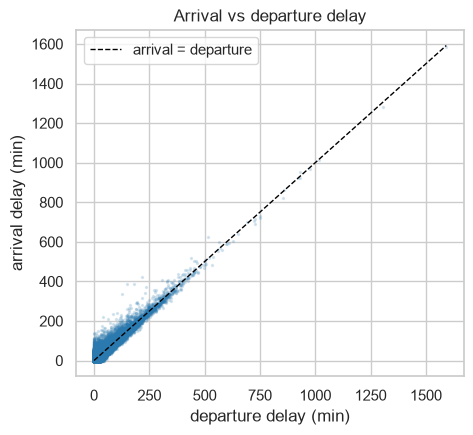

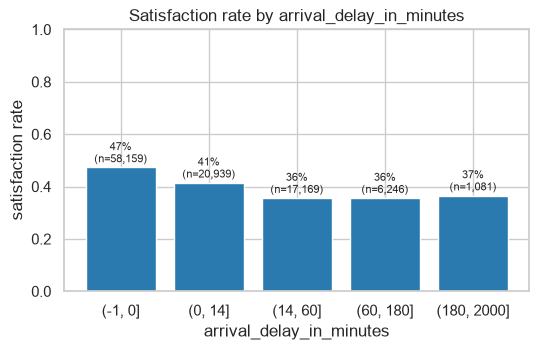

In [10]:
viz.plot_delay_relationship(X_train, FIGURES);
delays = X_train[["departure_delay_in_minutes", "arrival_delay_in_minutes"]].dropna()
difference = delays["arrival_delay_in_minutes"] - delays["departure_delay_in_minutes"]
print(f"correlation departure/arrival: {delays.corr().iloc[0, 1]:.3f}")
print(f"arrival - departure: median {difference.median():.0f} min, IQR [{difference.quantile(.25):.0f}, {difference.quantile(.75):.0f}]")
print(f"flights with no departure delay: {(X_train['departure_delay_in_minutes'] == 0).mean():.1%}")
viz.plot_rate_by_bins(X_train, y_train, "arrival_delay_in_minutes", [-1, 0, 14, 60, 180, 2000], FIGURES, "09_rate_by_delay");

**Interpretation**

- Arrival and departure delays are almost the same variable (**correlation 0.97**, median difference 0 minutes):
  a plane that leaves late arrives late. This justifies **filling the 310 missing arrival delays with the departure
  delay**, and keeping **only one of the two** in the model (we keep the arrival delay, the one the passenger
  experiences at the end of the trip).
- 56 % of flights leave on time. Satisfaction is **47 % when the plane arrives on time**, 41 % for small delays
  (1–14 minutes), about **36 % from 15 minutes**, and then stays flat even for delays of several hours.
  The effect is a threshold, so we add a binary feature **`is_delayed` (arrival delay ≥ 15 minutes)**,
  the usual airline definition of a late flight.
- Delays matter much less than the services (correlation −0.06): passengers forgive a delay more easily than a
  bad seat or a bad boarding experience.

## 5. Redundancy between ratings

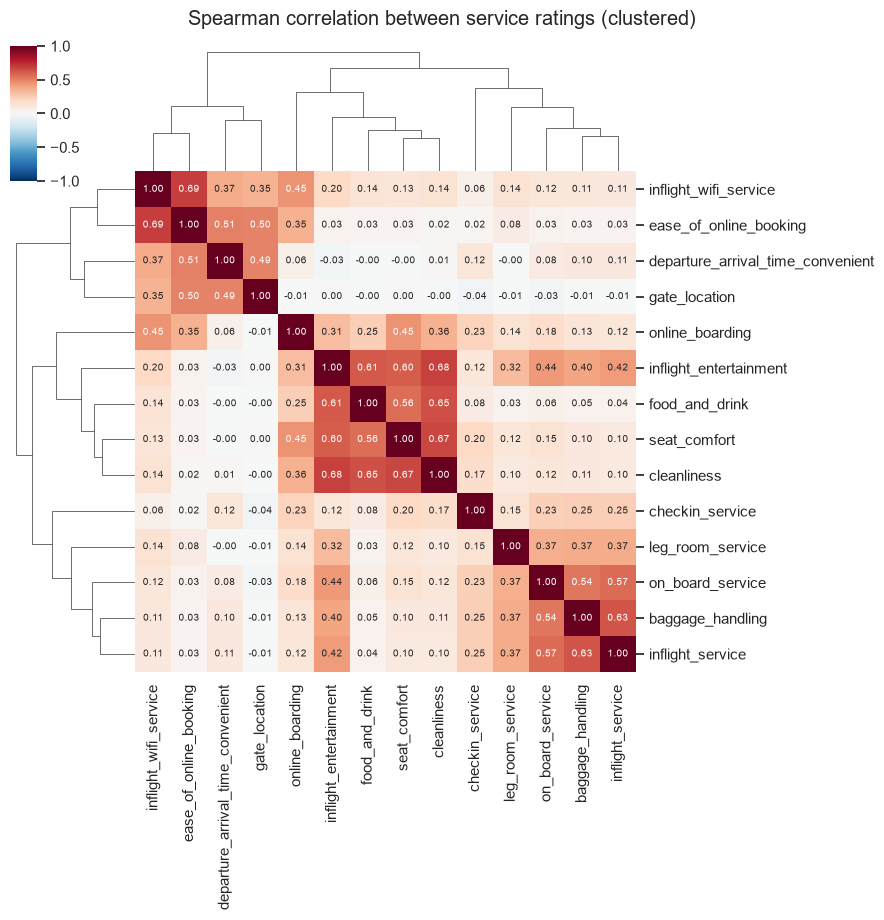

In [11]:
viz.plot_correlation_heatmap(X_train[RATINGS].replace(0, np.nan), FIGURES);

**Interpretation**

The clustered correlation matrix (zeros treated as missing) shows **three blocks of services**:

| Block | Services | Typical correlation |
|---|---|---|
| Digital and convenience | wifi, ease of online booking, gate location, departure/arrival time | 0.35–0.69 |
| Comfort | food and drink, seat comfort, inflight entertainment, cleanliness | 0.56–0.68 |
| Staff service | on-board service, inflight service, baggage handling, leg room, check-in | 0.23–0.63 |

Online boarding is linked to several blocks at once and is the strongest predictor, so we keep it on its own.

This redundancy has two consequences: (1) logistic-regression coefficients of correlated ratings become unstable
and hard to interpret; (2) LDA and QDA estimate a covariance matrix that becomes badly conditioned.
**Feature engineering decision:** we compute a **score per block** (mean of its ratings). The models will be
compared with the 14 raw ratings (`rating_representation: raw`) and with the compact version
(`rating_representation: grouped` = online boarding + 3 scores).

## 6. Interactions between categories

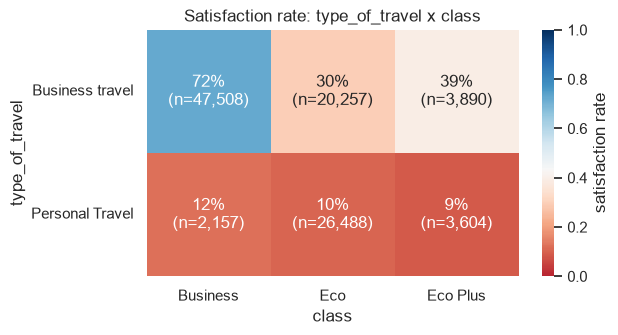

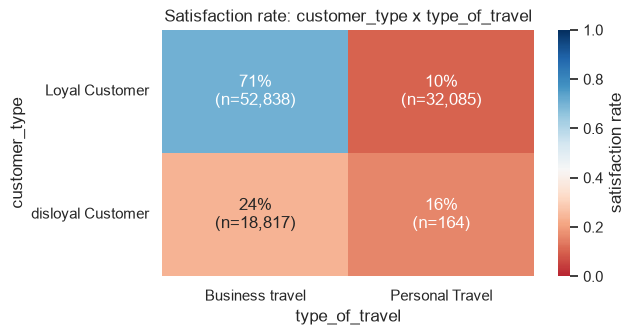

In [12]:
viz.plot_interaction(X_train, y_train, "type_of_travel", "class", FIGURES, "10_travel_x_class");
viz.plot_interaction(X_train, y_train, "customer_type", "type_of_travel", FIGURES, "11_customer_x_travel");

**Interpretation**

- **The class only matters for business trips:** 72 % of business travellers in Business class are satisfied,
  against 30 % in Eco and 39 % in Eco Plus. For personal trips, satisfaction stays around **9–12 % whatever the
  class**. The effects of class and type of travel do not simply add up.
- A linear model (logistic regression, LDA) only adds effects, so it cannot learn this by itself.
  **Feature engineering decision:** create the combined category **`travel_class`** (type of travel × class,
  6 levels). It replaces the two original columns in the model, which avoids duplicated information.
- Loyalty also mostly matters for business trips (71 % satisfied for loyal business travellers vs 24 % for disloyal
  ones). We keep this as a candidate interaction if the models need it.

## 7. Feature engineering

All the steps are implemented in `src/preprocessing.py` (class `FeatureEngineer`) and controlled by
`configs/config.yaml`. The medians are learned on the training set only (`fit`) and reused on the test set
(`transform`), so no information from the test set leaks into training.

| Step | What we do | Why (evidence) |
|---|---|---|
| Missing arrival delay | Fill with the departure delay | Correlation 0.97, median difference 0 (section 4) |
| Rating = 0 | Flag `<service>_not_applicable`, then replace by the training median | 0 means "not applicable", with very different satisfaction rates (section 3.1) |
| Rating blocks | Mean score per block: digital and convenience, comfort, staff service | Strong correlations inside each block (section 5) |
| Distance and delays | `log(1 + x)` | Skewness 1.1 and 6.7 (section 2) |
| Late flight | `is_delayed` = arrival delay ≥ 15 min | Satisfaction drops at 15 min, then stays flat (section 4) |
| Age | Age groups in addition to raw age | Inverted-U effect (section 2) |
| Travel × class | Combined category `travel_class` | Class only matters for business trips (section 6) |
| Departure delay | Not used by the model | Duplicate of the arrival delay |
| Encoding and scaling | One-hot encoding of categories, standardisation of numeric columns | Needed by KNN (distances) and logistic regression (gradient) |

In [13]:
engineer = build_feature_engineer(config).fit(X_train)
X_train_fe = engineer.transform(X_train)
new_columns = [c for c in X_train_fe.columns if c not in X_train.columns]
print("new columns:", new_columns)
print("missing values after engineering:", int(X_train_fe.isna().sum().sum()))
display(X_train_fe[new_columns].head())

new columns: ['inflight_wifi_service_not_applicable', 'departure_arrival_time_convenient_not_applicable', 'ease_of_online_booking_not_applicable', 'online_boarding_not_applicable', 'leg_room_service_not_applicable', 'food_and_drink_not_applicable', 'digital_convenience_score', 'comfort_score', 'staff_service_score', 'log_flight_distance', 'log_departure_delay', 'log_arrival_delay', 'is_delayed', 'age_group', 'travel_class']
missing values after engineering: 0


,inflight_wifi_service_not_applicable,departure_arrival_time_convenient_not_applicable,ease_of_online_booking_not_applicable,online_boarding_not_applicable,leg_room_service_not_applicable,food_and_drink_not_applicable,digital_convenience_score,comfort_score,staff_service_score,log_flight_distance,log_departure_delay,log_arrival_delay,is_delayed,age_group,travel_class
0,0,0,0,0,0,0,2.75,5.00,4.0,6.133398,3.258097,2.944439,1,under_18,Personal Travel | Eco Plus
1,0,0,0,0,0,0,2.75,1.00,2.8,5.463832,0.693147,1.945910,0,18_25,Business travel | Business
2,0,0,0,0,0,0,2.00,5.00,3.8,7.041412,0.000000,0.000000,0,26_39,Business travel | Business
3,0,0,0,0,0,0,4.25,2.00,3.0,6.333280,2.484907,2.302585,0,18_25,Business travel | Business
4,0,0,0,0,0,0,3.00,3.75,3.4,5.370638,0.000000,0.000000,0,60_plus,Business travel | Business


,correlation with target
staff_service_score,0.392
comfort_score,0.370
log_flight_distance,0.250
inflight_wifi_service_not_applicable,0.200
digital_convenience_score,0.178
ease_of_online_booking_not_applicable,0.099
online_boarding_not_applicable,0.038
departure_arrival_time_convenient_not_applicable,0.020
food_and_drink_not_applicable,0.002
leg_room_service_not_applicable,-0.011


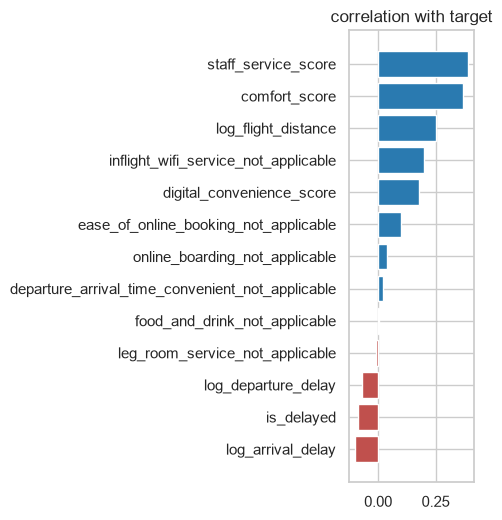

In [14]:
numeric_new = [c for c in new_columns if pd.api.types.is_numeric_dtype(X_train_fe[c])]
engineered_relevance = pd.DataFrame({"correlation with target": X_train_fe[numeric_new].corrwith(y_train)})
display(engineered_relevance.sort_values("correlation with target", ascending=False).round(3))
viz.plot_feature_relevance(engineered_relevance, FIGURES, "12_engineered_feature_relevance");

**Interpretation**

- The engineering adds **15 columns** and leaves **no missing value**.
- The **staff service** (0.39) and **comfort** (0.37) scores are almost as related to satisfaction as the best
  single ratings, while each one summarises 4 or 5 columns. The **digital and convenience** score is weaker (0.18)
  because it contains the two uninformative services (gate location, departure/arrival time).
- The log makes the delay more useful for a linear model: **−0.10 for `log_arrival_delay`** against −0.06 for the
  raw delay. `is_delayed` (−0.09) captures the same threshold effect in a single, easy-to-explain feature.
- The **wifi "not applicable" flag** alone reaches 0.20, as much as several real ratings. This is the
  suspicious 99.7 % seen in section 3.1: we will measure how much the final model relies on it.
  The other flags are weak (0.10 or less) and may be removed if the models do not use them.

## 8. Preliminary check: does the feature engineering help?

To measure the effect of the representation (and not of the model), we train the **same simple model**,
a logistic regression from the course, with three representations, using **5-fold stratified cross-validation
on the training set only**. This is a quick check, not the final model selection.

In [15]:
import copy
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline

grouped_config = copy.deepcopy(config)
grouped_config["feature_engineering"]["rating_representation"] = "grouped"
representations = {
    "baseline (raw columns)": build_baseline_preprocessor(config),
    "engineered, 14 raw ratings": build_preprocessor(config),
    "engineered, grouped ratings": build_preprocessor(grouped_config),
}
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=config["seed"])
rows = {}
for name, preprocessor in representations.items():
    model = make_pipeline(preprocessor, LogisticRegression(max_iter=2000))
    scores = cross_validate(model, X_train, y_train, cv=folds, scoring=["accuracy", "f1", "roc_auc"])
    n_features = preprocessor.fit(X_train, y_train).transform(X_train.head()).shape[1]
    rows[name] = {"features": n_features,
                  **{m: scores[f"test_{m}"].mean() for m in ["accuracy", "f1", "roc_auc"]}}
comparison = pd.DataFrame(rows).T.astype({"features": int})
display(comparison.round(4))

,features,accuracy,f1,roc_auc
baseline (raw columns),23,0.8752,0.8531,0.9267
"engineered, 14 raw ratings",35,0.9046,0.8896,0.9658
"engineered, grouped ratings",25,0.8920,0.8734,0.9553


**Interpretation**

- With the **same model**, the engineered representation raises accuracy from **0.875 to 0.905**, F1 from
  0.853 to 0.890 and ROC-AUC from 0.927 to **0.966**. The preprocessing choices clearly change the results,
  which is the main point the project guidelines ask us to analyse.
- The **grouped** representation (25 features) loses about 1.3 accuracy points compared with the 14 raw ratings
  (35 features), but still beats the baseline with almost the same number of features (23). It is the more
  interpretable option: one coefficient per block of services instead of 14 correlated ones.
- These are cross-validation scores on the training set only; the test file has not been used yet.

## 9. Summary and next steps

**What drives satisfaction (first answers to the project question)**

1. **The type of trip and the class**: business travellers in Business class are satisfied 72 % of the time;
   personal travellers only about 10 %, whatever the class.
2. **Online boarding** is the most important service, followed by **inflight entertainment, seat comfort,
   on-board service, leg room and cleanliness**. For most services the jump happens between a rating of 3 and 4.
3. **Inflight wifi** has a strong threshold effect: a rating of 5 means 99 % satisfaction.
4. **Delays** matter less than the services: satisfaction drops by about 11 points once the delay reaches
   15 minutes, then stays flat.
5. **Gender, gate location and departure/arrival time convenience** carry almost no information.

**Feature engineering retained**: fill the arrival delay with the departure delay; flag and impute the
"not applicable" ratings; log of distance and delay; `is_delayed`; age groups; travel × class category;
optional block scores. It improves a plain logistic regression by about 3 accuracy points.

**Next steps**

- Measure the contribution of each engineering step separately (ablation study).
- Train the models of the course (logistic regression, KNN, LDA, QDA) with a hyperparameter search in
  cross-validation, then compare them.
- Explain the best model (coefficients, permutation importance) and check its dependence on the wifi flag.
- Evaluate once on `test.csv`, then write `main.py` (training) and `test.py` (inference).